# COMPREHENSIVE SALES FORECASTING ANALYSIS

## Machine Learning Project: EDA, Feature Engineering, SVR, and Decision Tree Models

**Dataset:** K234131595 – Sales Prediction Analysis

### Key Corrections Applied:
- [OK] NO OUTLIER REMOVAL – Keep all data and discuss outlier impact instead.
- [OK] NO LAG/ROLLING FEATURES – Not appropriate because the dataset has only 4 distinct dates.
- [OK] TIME-BASED SPLIT – Use earlier dates for training and the last date for testing.
- [OK] TRAIN-ONLY PREPROCESSING – Fit encoders/scalers on the training set only.
- [OK] TRAIN-ONLY GROUP AVERAGES – Group mean features are computed using training data only.



In [108]:
from google.colab import drive
drive.mount('/content/drive')
EXCEL_PATH = "/content/drive/MyDrive/MACHINE LEARNING/Data/K234131595.csv"

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [109]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.svm import SVR
from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

warnings.filterwarnings("ignore")

print("=" * 100)
print("COMPREHENSIVE SALES FORECASTING ANALYSIS")
print("=" * 100)
print("Machine Learning Project: EDA, Feature Engineering, SVR, and Decision Tree Models")

COMPREHENSIVE SALES FORECASTING ANALYSIS
Machine Learning Project: EDA, Feature Engineering, SVR, and Decision Tree Models


## QUESTION 1: EXPLORATORY DATA ANALYSIS (EDA) AND SUMMARY STATISTICS
### Question 1.a: Data Loading and Summary Statistics


In [110]:
df = pd.read_csv(EXCEL_PATH)
df['date'] = pd.to_datetime(df['date'])

print(f"\n[OK] Data loaded: {df.shape[0]} records, {df.shape[1]} columns")
print(f"[OK] Date range: {df['date'].min()} to {df['date'].max()}")
print(f"[OK] Unique dates: {df['date'].nunique()} ({sorted(df['date'].unique())})")
print(f"[OK] Unique stores: {df['store_nbr'].nunique()}")
print(f"[OK] Unique items: {df['item_nbr'].nunique()}")


[OK] Data loaded: 633 records, 13 columns
[OK] Date range: 2013-01-01 00:00:00 to 2013-02-12 00:00:00
[OK] Unique dates: 4 ([Timestamp('2013-01-01 00:00:00'), Timestamp('2013-01-05 00:00:00'), Timestamp('2013-02-11 00:00:00'), Timestamp('2013-02-12 00:00:00')])
[OK] Unique stores: 46
[OK] Unique items: 23


In [111]:
df = pd.read_csv(EXCEL_PATH)
print("Shape:", df.shape)
print("\nColumns:", df.columns.tolist())
print("\nHead:")
display(df.head())

Shape: (633, 13)

Columns: ['date', 'store_nbr', 'item_nbr', 'type', 'cluster', 'state', 'family', 'class', 'perishable', 'store_type', 'family_encoded', 'state_encoded', 'unit_sales']

Head:


,date,store_nbr,item_nbr,type,cluster,state,family,class,perishable,store_type,family_encoded,state_encoded,unit_sales
0,2013-01-01,25,177050,D,1,Santa Elena,LINGERIE,7034,0,3,9,0,1.0
1,2013-01-01,25,509877,D,1,Santa Elena,LINGERIE,7034,0,3,9,0,1.0
2,2013-01-01,25,655840,D,1,Santa Elena,LINGERIE,7034,0,3,9,0,3.0
3,2013-01-05,1,115847,D,13,Pichincha,LINGERIE,7034,0,3,9,1,8.0
4,2013-01-05,1,215468,D,13,Pichincha,LINGERIE,7034,0,3,9,1,4.0


In [112]:
# 3. BASIC DATA CHECKS
df["date"] = pd.to_datetime(df["date"])

print("Missing values by column:")
display(df.isnull().sum())

print("\nDuplicated rows:", df.duplicated().sum())
print("\nDate range:", df["date"].min(), "to", df["date"].max())
print("Number of distinct dates:", df["date"].nunique())
print("\nObservations by date:")
display(df["date"].value_counts().sort_index())

Missing values by column:


,0
date,0
store_nbr,0
item_nbr,0
type,0
cluster,0
state,0
family,0
class,0
perishable,0
store_type,0



Duplicated rows: 0

Date range: 2013-01-01 00:00:00 to 2013-02-12 00:00:00
Number of distinct dates: 4

Observations by date:


,count
date,
2013-01-01,3
2013-01-05,221
2013-02-11,195
2013-02-12,214


##### The dataset has no missing values and no duplicated rows, which indicates good basic data quality. The date range runs from 2013-01-01 to 2013-02-12, covering 4 distinct dates. The number of observations is uneven across dates, which should be considered when applying time-based splitting and feature engineering.

In [113]:

# 4. SUMMARY STATISTICS FOR MAIN NUMERICAL VARIABLES
numerical_cols_for_stats = ["store_nbr","item_nbr","store_type","family_encoded","state_encoded", "unit_sales", "cluster", "class", "perishable"]

desc_stats = (
    df[numerical_cols_for_stats]
    .agg(["mean", "median", "std", "min", "max"])
    .T
    .round(4)
)

display(desc_stats)


,mean,median,std,min,max
store_nbr,24.7314,25.0,16.7202,1.0,54.0
item_nbr,579340.0079,514446.0,269086.6941,115847.0,1005465.0
store_type,1.9953,2.0,1.2254,0.0,4.0
family_encoded,11.0521,9.0,4.0611,9.0,20.0
state_encoded,4.3333,1.0,4.1021,0.0,14.0
unit_sales,3.2923,2.0,6.8190,1.0,91.0
cluster,8.3081,8.0,4.4603,1.0,17.0
class,6952.3017,7034.0,157.8801,6155.0,7034.0
perishable,0.0000,0.0,0.0000,0.0,0.0


### Question 1.b. Visualizations and Pattern Discovery

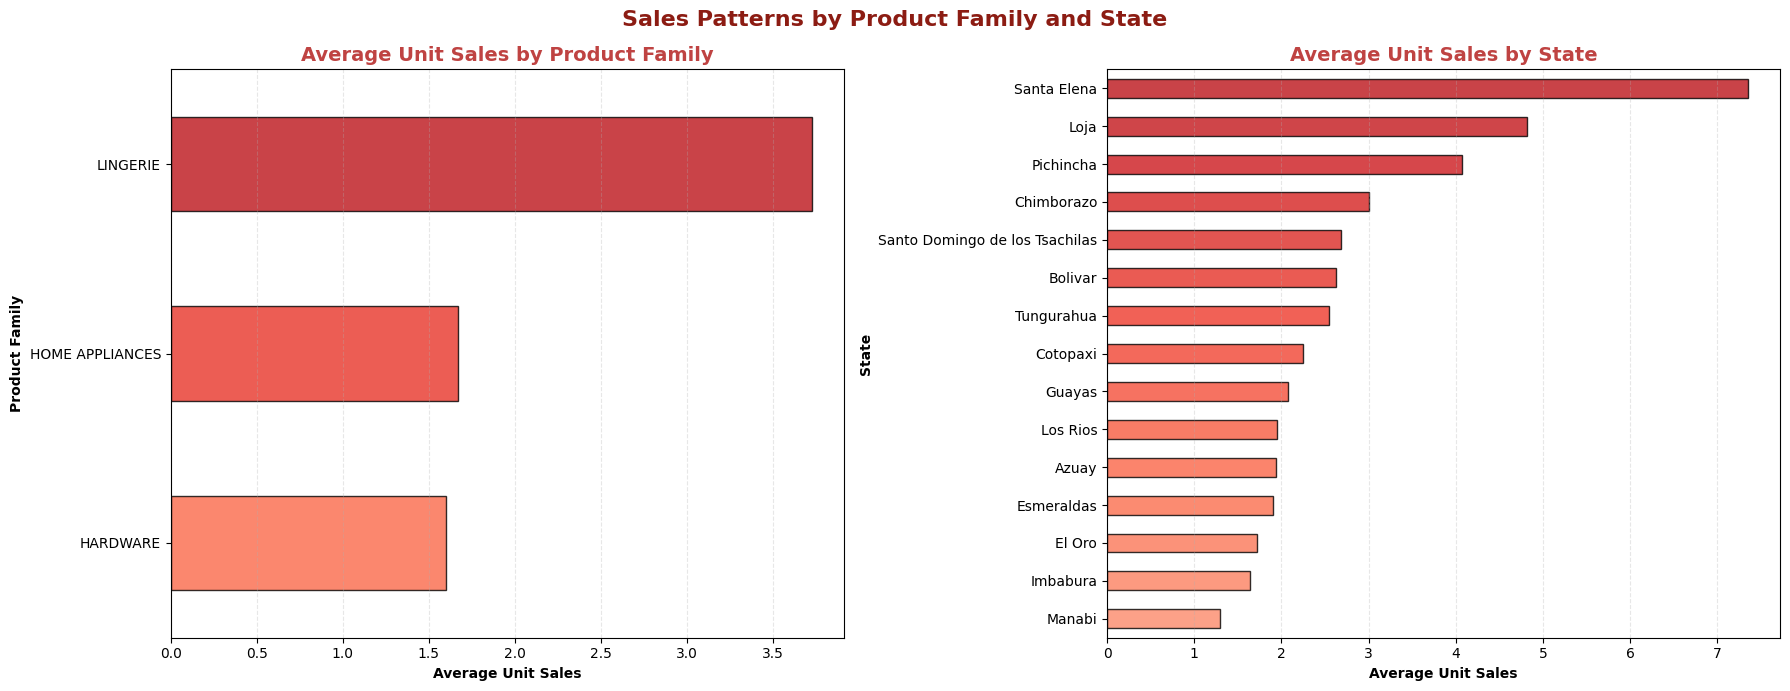

In [114]:
import matplotlib.pyplot as plt
import numpy as np

# ============================================================================================
# VISUALIZATION: PRODUCT FAMILY & STATE ANALYSIS (HORIZONTAL LAYOUT)
# ============================================================================================

# 1. Prepare grouped average sales data
family_sales = df.groupby("family")["unit_sales"].mean().sort_values(ascending=True)
state_sales = df.groupby("state")["unit_sales"].mean().sort_values(ascending=True)

# 2. Create figure with 1 row and 2 columns
fig, axes = plt.subplots(1, 2, figsize=(18, 7))
fig.suptitle("Sales Patterns by Product Family and State", fontsize=16, fontweight="bold", color="#8C1C13")

# --- VISUALIZATION 1: AVERAGE UNIT SALES BY PRODUCT FAMILY ---
family_sales.plot(
    kind="barh",
    ax=axes[0],
    color=plt.cm.Reds(np.linspace(0.5, 0.8, len(family_sales))),
    edgecolor="black",
    alpha=0.8
)
axes[0].set_title("Average Unit Sales by Product Family", fontsize=14, fontweight="bold", color="#BF4342")
axes[0].set_xlabel("Average Unit Sales", fontweight="bold")
axes[0].set_ylabel("Product Family", fontweight="bold")
axes[0].grid(axis="x", linestyle="--", alpha=0.3)

# --- VISUALIZATION 2: AVERAGE UNIT SALES BY STATE ---
state_sales.plot(
    kind="barh",
    ax=axes[1],
    color=plt.cm.Reds(np.linspace(0.4, 0.8, len(state_sales))),
    edgecolor="black",
    alpha=0.8
)
axes[1].set_title("Average Unit Sales by State", fontsize=14, fontweight="bold", color="#BF4342")
axes[1].set_xlabel("Average Unit Sales", fontweight="bold")
axes[1].set_ylabel("State", fontweight="bold")
axes[1].grid(axis="x", linestyle="--", alpha=0.3)

plt.tight_layout()
plt.show()

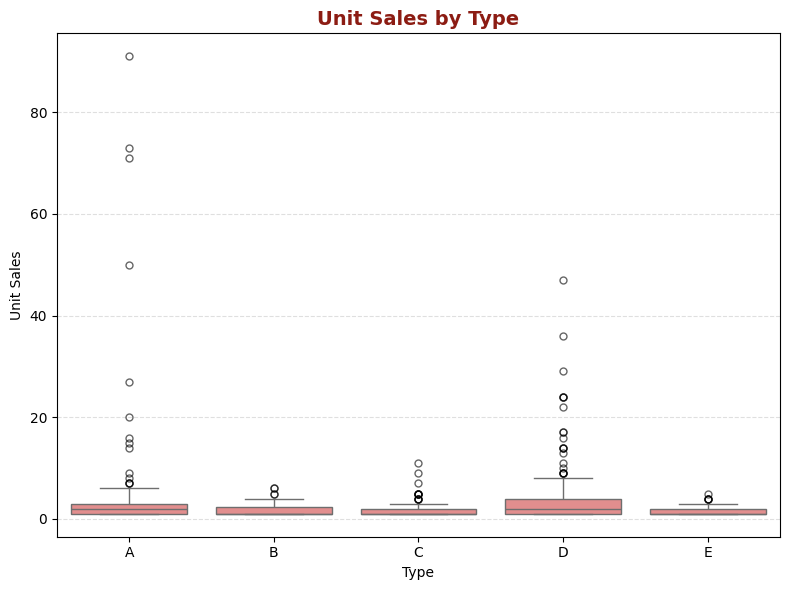

In [115]:
plt.figure(figsize=(8, 6))

sns.boxplot(
    data=df,
    x="type",
    y="unit_sales",
    order=["A", "B", "C", "D", "E"],
    color="#F08080",
    flierprops=dict(
        marker='o',
        markersize=5,
        markerfacecolor='none',
        markeredgecolor='black',
        markeredgewidth=1,
        alpha=0.6
    )
)

plt.title("Unit Sales by Type", fontsize=14, fontweight="bold", color="#8C1C13")
plt.xlabel("Type")
plt.ylabel("Unit Sales")
plt.grid(axis="y", linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()

[OK] Q1b_Time_Series.png


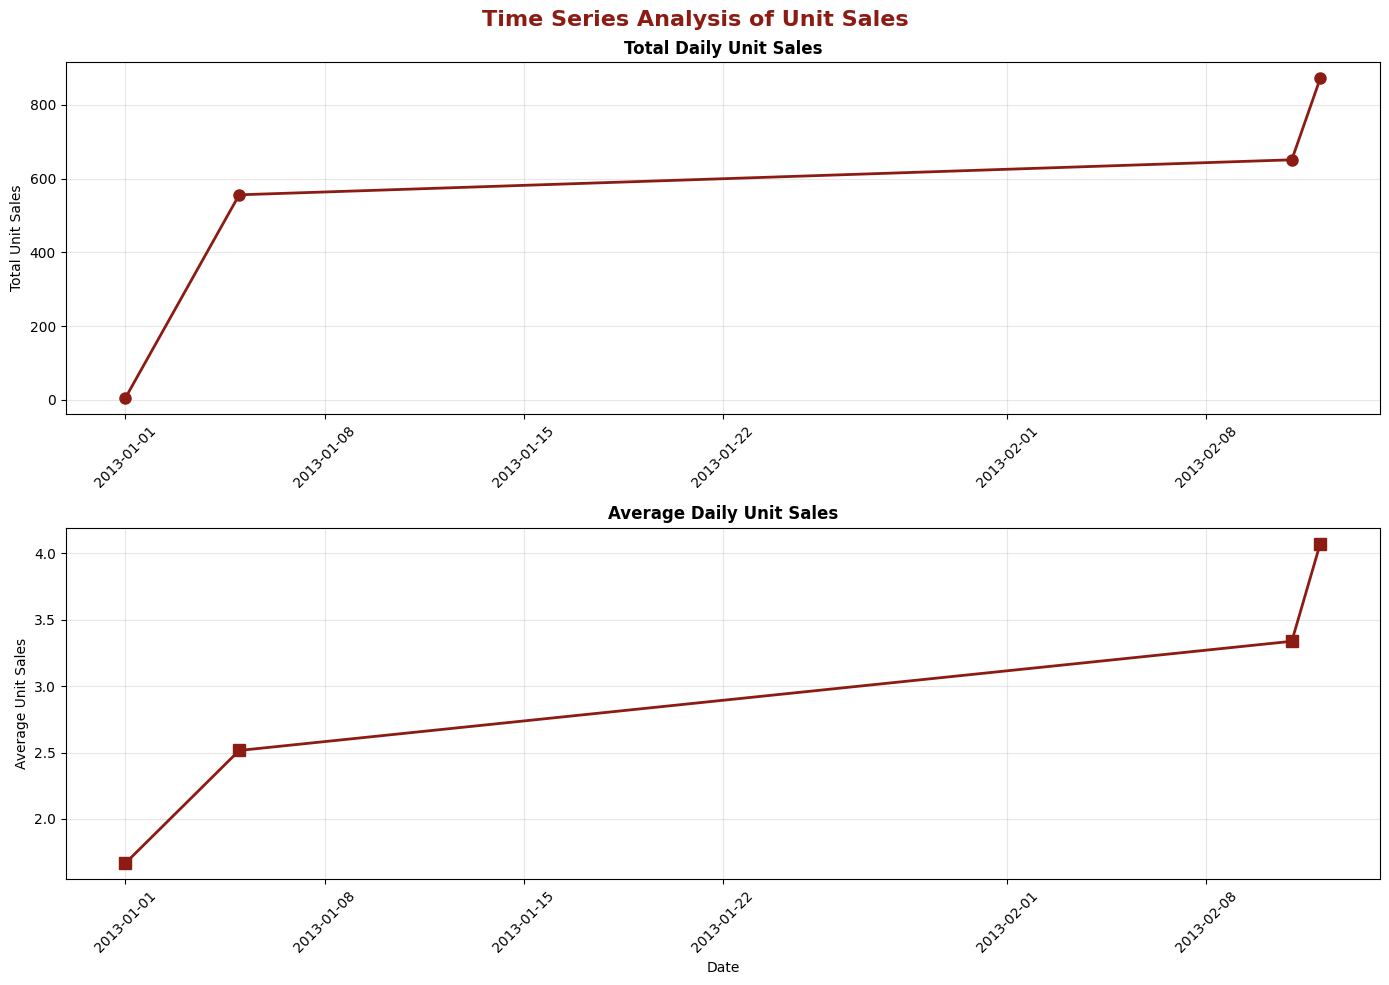

In [116]:
# Time series
print("[OK] Q1b_Time_Series.png")

time_series_data = df.groupby("date")["unit_sales"].agg(["sum", "mean", "count"]).reset_index()

fig, axes = plt.subplots(2, 1, figsize=(14, 10))
fig.suptitle("Time Series Analysis of Unit Sales", fontsize=16, fontweight="bold", color="#8C1C13")

axes[0].plot(time_series_data["date"], time_series_data["sum"],
             color="#8C1C13", linewidth=2, marker="o", markersize=8)
axes[0].set_title("Total Daily Unit Sales", fontweight="bold")
axes[0].set_ylabel("Total Unit Sales")
axes[0].grid(alpha=0.3)
axes[0].tick_params(axis="x", rotation=45)

axes[1].plot(time_series_data["date"], time_series_data["mean"],
             color="#8C1C13", linewidth=2, marker="s", markersize=8)
axes[1].set_title("Average Daily Unit Sales", fontweight="bold")
axes[1].set_xlabel("Date")
axes[1].set_ylabel("Average Unit Sales")
axes[1].grid(alpha=0.3)
axes[1].tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.savefig("Q1b_Time_Series.png", dpi=300, bbox_inches="tight")
plt.show()

### Question 1.c. Outlier Detection and Impact Analysis

[OK] Q1c_Outlier_Analysis.png


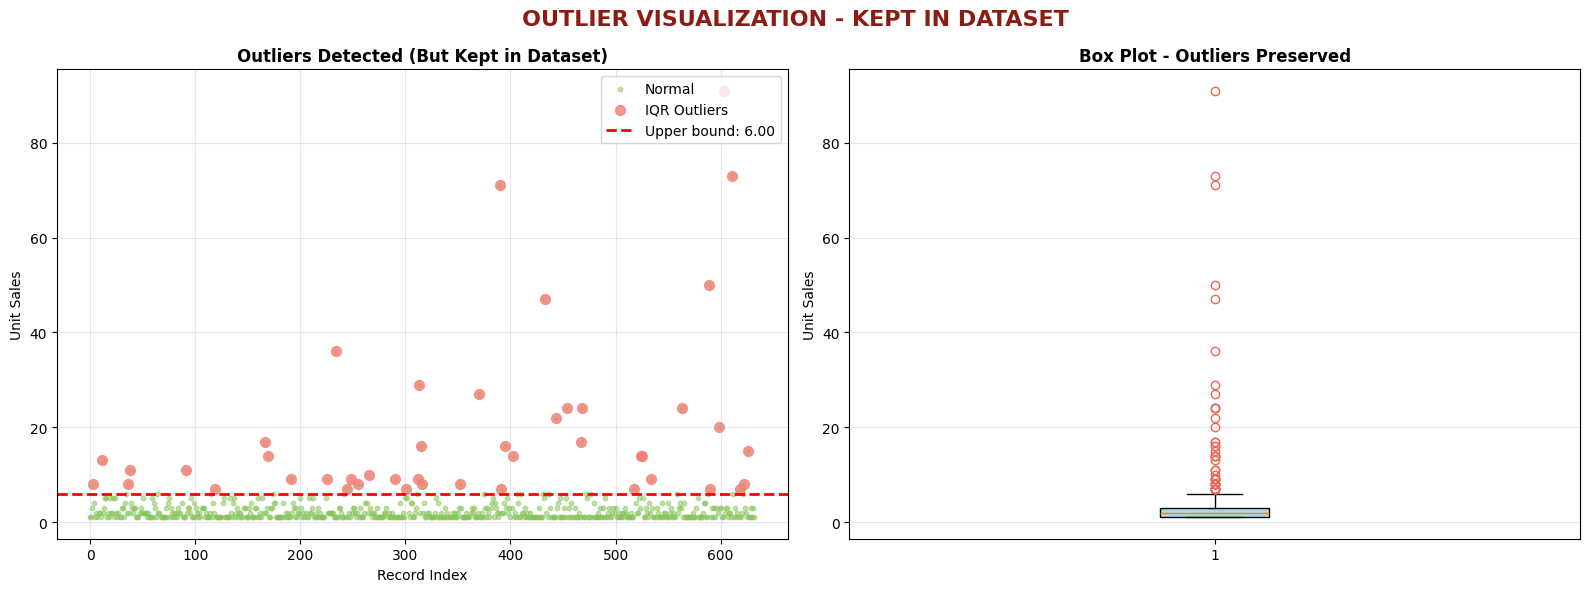

In [117]:
# Outlier Visualization
print("[OK] Q1c_Outlier_Analysis.png")
Q1 = df['unit_sales'].quantile(0.25)
Q3 = df['unit_sales'].quantile(0.75)
IQR = Q3 - Q1
upper_bound = Q3 + 1.5 * IQR
outlier_indices = df[df['unit_sales'] > upper_bound].index

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
fig.suptitle('OUTLIER VISUALIZATION - KEPT IN DATASET', fontsize=16, fontweight='bold', color="#8C1C13")

axes[0].scatter(range(len(df)), df['unit_sales'], c='#85c458', alpha=0.5, s=10, label='Normal')
axes[0].scatter(outlier_indices, df.loc[outlier_indices, 'unit_sales'], c='#F28076', alpha=0.8,
               s=50, label='IQR Outliers', marker='o', edgecolors='#F28076')
axes[0].axhline(y=upper_bound, color='red', linestyle='--', linewidth=2, label=f'Upper bound: {upper_bound:.2f}')
axes[0].set_title('Outliers Detected (But Kept in Dataset)', fontweight='bold')
axes[0].set_xlabel('Record Index')
axes[0].set_ylabel('Unit Sales')
axes[0].legend(loc='upper right')
axes[0].grid(alpha=0.3)

bp = axes[1].boxplot(df['unit_sales'], vert=True, patch_artist=True, flierprops=dict(marker='o', markerfacecolor='none', markeredgecolor='#EE6457', markersize=6))
bp['boxes'][0].set_facecolor('#ADD8E6')
axes[1].set_title('Box Plot - Outliers Preserved', fontweight='bold')
axes[1].set_ylabel('Unit Sales')
axes[1].grid(alpha=0.3, axis='y')

plt.tight_layout()
plt.savefig("Q1c_Outlier_Analysis.png", dpi=300, bbox_inches="tight")
plt.show()

In [118]:
# Outlier detection (IQR and Z-score methods)
from scipy.stats import zscore

Q1 = df['unit_sales'].quantile(0.25)
Q3 = df['unit_sales'].quantile(0.75)
IQR = Q3 - Q1
lower_bound_iqr = Q1 - 1.5 * IQR
upper_bound_iqr = Q3 + 1.5 * IQR

outliers_iqr = df[(df['unit_sales'] < lower_bound_iqr) | (df['unit_sales'] > upper_bound_iqr)]
outliers_iqr_indices = outliers_iqr.index

print(f"Outlier Detection Results:")
print(f"  Q1 (25th percentile): {Q1:.2f}")
print(f"  Q3 (75th percentile): {Q3:.2f}")
print(f"  IQR: {IQR:.2f}")
print(f"  Lower bound: {lower_bound_iqr:.2f}")
print(f"  Upper bound: {upper_bound_iqr:.2f}")
print(f"  [OK] IQR Method: {len(outliers_iqr)} outliers ({len(outliers_iqr)/len(df)*100:.2f}%) - KEPT IN DATA")

# Z-score Method
z_scores = np.abs(zscore(df['unit_sales']))
outliers_zscore = df[z_scores > 3]
print(f"  [OK] Z-Score Method: {len(outliers_zscore)} outliers ({len(outliers_zscore)/len(df)*100:.2f}%) - KEPT IN DATA")

Outlier Detection Results:
  Q1 (25th percentile): 1.00
  Q3 (75th percentile): 3.00
  IQR: 2.00
  Lower bound: -2.00
  Upper bound: 6.00
  [OK] IQR Method: 45 outliers (7.11%) - KEPT IN DATA
  [OK] Z-Score Method: 11 outliers (1.74%) - KEPT IN DATA


## Question 2: Feature Engineering and Modeling Rationale
### Question 2.a. Feature Engineering Construction


In [119]:
print("\n" + "="*100)
print("STEP 3: TIME-BASED TRAIN-TEST SPLIT")
print("="*100)

# Ensure correct date format
df["date"] = pd.to_datetime(df["date"])

# Sort unique dates
unique_dates = sorted(df["date"].unique())
print(f"Available dates in the dataset: {unique_dates}")

# Use the last date as the test set
test_date = unique_dates[-1]

# Split data
train_df = df[df["date"] < test_date].copy()
test_df = df[df["date"] == test_date].copy()

print(f"\n[OK] DATA SPLIT COMPLETED:")
print(f" - Training dates: {[d.date() for d in unique_dates[:-1]]}")
print(f" - Test date: {test_date.date()}")
print(f" - Number of observations: Train ({len(train_df)} rows) | Test ({len(test_df)} rows)")


STEP 3: TIME-BASED TRAIN-TEST SPLIT
Available dates in the dataset: [Timestamp('2013-01-01 00:00:00'), Timestamp('2013-01-05 00:00:00'), Timestamp('2013-02-11 00:00:00'), Timestamp('2013-02-12 00:00:00')]

[OK] DATA SPLIT COMPLETED:
 - Training dates: [datetime.date(2013, 1, 1), datetime.date(2013, 1, 5), datetime.date(2013, 2, 11)]
 - Test date: 2013-02-12
 - Number of observations: Train (419 rows) | Test (214 rows)


### Question 2.b. Modeling Rationale and Feature Justification

In [120]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import StandardScaler

# ============================================================================================
# STEP 4: FEATURE ENGINEERING (TEMPORAL & GROUP AVERAGES)
# ============================================================================================
print("\n" + "="*100)
print("FEATURE ENGINEERING - TEMPORAL & GROUP AVERAGES")
print("="*100)

# 1. Create basic temporal features only
for df_temp in [train_df, test_df]:
    df_temp['day_of_week'] = df_temp['date'].dt.dayofweek
    df_temp['is_weekend'] = (df_temp['day_of_week'] >= 5).astype(int)
    # Add the missing 'month' and 'day_of_month' features
    df_temp['month'] = df_temp['date'].dt.month
    df_temp['day_of_month'] = df_temp['date'].dt.day
    # Month is not very informative because the data only contains January and February,
    # but it can still be retained as a calendar-related feature

# 2. Use a train-only target mean encoding function
def add_train_mean_feature(train, test, group_col, new_col):
    mapping = train.groupby(group_col)['unit_sales'].mean()
    global_mean = train['unit_sales'].mean()
    train[new_col] = train[group_col].map(mapping).fillna(global_mean)
    test[new_col] = test[group_col].map(mapping).fillna(global_mean)

add_train_mean_feature(train_df, test_df, "item_nbr", "avg_item_sales")
add_train_mean_feature(train_df, test_df, "store_nbr", "avg_store_sales")
add_train_mean_feature(train_df, test_df, "family", "avg_family_sales")
add_train_mean_feature(train_df, test_df, "cluster", "avg_cluster_sales")

print("\n[CHECK] First 10 rows of train_df after adding engineered features:")
print(train_df[['date', 'unit_sales', 'avg_item_sales', 'avg_store_sales', 'day_of_week', 'month', 'day_of_month']].head(10))

# ============================================================================================
# STEP 5: PREPROCESSING & SCALING
# ============================================================================================
print("\n" + "="*100)
print("PREPROCESSING - SCALING")
print("="*100)

feature_cols = [
    'cluster', 'perishable', 'day_of_week', 'month', 'day_of_month', 'is_weekend',
    'avg_item_sales', 'avg_store_sales', 'avg_family_sales', 'avg_cluster_sales'
]

X_train = train_df[feature_cols].fillna(0)
X_test = test_df[feature_cols].fillna(0)
y_train = train_df['unit_sales']
y_test = test_df['unit_sales']

# StandardScaler
scaler = StandardScaler()
X_train_scaled_np = scaler.fit_transform(X_train)
X_test_scaled_np = scaler.transform(X_test)

# Convert back to DataFrame for easier inspection
X_train_scaled = pd.DataFrame(X_train_scaled_np, columns=feature_cols, index=X_train.index)
X_test_scaled = pd.DataFrame(X_test_scaled_np, columns=feature_cols, index=X_test.index)

print("\n[CHECK] First 10 rows of X_train after scaling:")
print(X_train_scaled.head(10))

print(f"\n[OK] Preprocessing completed.")


FEATURE ENGINEERING - TEMPORAL & GROUP AVERAGES

[CHECK] First 10 rows of train_df after adding engineered features:
        date  unit_sales  avg_item_sales  avg_store_sales  day_of_week  month  day_of_month
0 2013-01-01         1.0        2.454545         7.000000            1      1             1
1 2013-01-01         1.0        1.500000         7.000000            1      1             1
2 2013-01-01         3.0        1.857143         7.000000            1      1             1
3 2013-01-05         8.0        4.333333         2.888889            5      1             5
4 2013-01-05         4.0        3.235294         2.888889            5      1             5
5 2013-01-05         1.0        1.851852         2.888889            5      1             5
6 2013-01-05         2.0        1.500000         2.888889            5      1             5
7 2013-01-05         1.0        2.000000         2.888889            5      1             5
8 2013-01-05         2.0        2.687500         2.888

### Question 2.c. Bias-Variance Trade-off Analysis

In [121]:
print("\n" + "="*100)
print("========== Q2: CHECKING ENGINEERED FEATURES ==========")
print("="*100)

# Note: `df_feat` was not defined in the previous steps.
# To check the engineered features, we will use `train_df`,
# which is the dataframe that already contains temporal features,
# group-average features, and one-hot encoded variables.
target_df = train_df

# Update the list of engineered features that were actually created
# Based on the previous cells for temporal features, one-hot encoding, and group averages
eng_features = [
    'cluster', 'perishable', 'day_of_week', 'month', 'day_of_month', 'is_weekend',
    'avg_item_sales', 'avg_store_sales', 'avg_family_sales', 'avg_cluster_sales'
]

# Add the one-hot encoded columns for `store_type` if they exist
# The variable `store_type_cols` was created in the one-hot encoding step
if 'store_type_cols' in globals():
    eng_features.extend([col for col in store_type_cols if col in target_df.columns])
else:
    print("[WARN] 'store_type_cols' not found. Ensure the one-hot encoding cell was executed.")

# Filter only the features that actually exist in target_df to avoid KeyError
eng_features_to_check = [f for f in eng_features if f in target_df.columns]

if not eng_features_to_check:
    print("[WARN] No engineered features found to check based on the current `train_df` state or the `eng_features` list is empty.")
    print("       This cell requires prior feature engineering steps (temporal, group averages, one-hot encoding) to be executed.")
else:
    # Create a summary DataFrame
    feature_nan_df = pd.DataFrame({
        "Feature": eng_features_to_check,
        "NaN_Count": [target_df[feat].isnull().sum() for feat in eng_features_to_check],
        "NaN_Percent": [f"{(target_df[feat].isnull().sum()/len(target_df))*100:.2f}%" for feat in eng_features_to_check],
        "Min": [target_df[feat].min() for feat in eng_features_to_check],
        "Max": [target_df[feat].max() for feat in eng_features_to_check]
    })

    # Display the summary table
    from IPython.display import display
    display(feature_nan_df)

    print("\n" + "-"*100)


========== Q2: CHECKING ENGINEERED FEATURES ==========


,Feature,NaN_Count,NaN_Percent,Min,Max
0,cluster,0,0.00%,1.000000,17.000000
1,perishable,0,0.00%,0.000000,0.000000
2,day_of_week,0,0.00%,0.000000,5.000000
3,month,0,0.00%,1.000000,2.000000
4,day_of_month,0,0.00%,1.000000,11.000000
5,is_weekend,0,0.00%,0.000000,1.000000
6,avg_item_sales,0,0.00%,1.458333,11.625000
7,avg_store_sales,0,0.00%,1.000000,10.555556
8,avg_family_sales,0,0.00%,1.700000,3.204819
9,avg_cluster_sales,0,0.00%,1.675000,5.200000



----------------------------------------------------------------------------------------------------


## Question 3: Variable Selection and Encoding Strategy
### Question 3.a. Variable Identification and Analysis

In [122]:
from sklearn.preprocessing import OneHotEncoder

print("=" * 100)
print("VARIABLE SELECTION AND ENCODING STRATEGY (Q3)")
print("=" * 100)

# --------------------------------------------------------------------------------------------
# PART A: DETAILED VARIABLE IDENTIFICATION (Based on the selected features)
# --------------------------------------------------------------------------------------------
print("\nPART A: VARIABLE IDENTIFICATION & RATIONALE")

# Analyze the target variable
print(f"""
1. PRIMARY TARGET: unit_sales (Numerical)
   • Type: Continuous numerical variable
   • Range: [{df['unit_sales'].min()}, {df['unit_sales'].max()}]
   • Mean: {df['unit_sales'].mean():.2f} | Skewness: {df['unit_sales'].skew():.3f}
   • Rationale: This is the target variable for sales forecasting.
     The right-skewed distribution indicates that high-volume sales days are preserved as outliers.

2. NUMERICAL PREDICTOR: cluster
   • Type: Discrete numerical variable
   • Unique Clusters: {df['cluster'].nunique()} (Values: {sorted(df['cluster'].unique())})
   • Rationale: Represents store groupings with similar economic environments.

3. CATEGORICAL PREDICTOR: store_type
   • Type: Nominal categorical variable
   • Unique Values: {df['store_type'].nunique()} (Categories: {sorted(df['store_type'].unique())})
   • Rationale: `store_type` is a categorical label representing different store formats and should not be treated as an ordered numerical variable.
""")

# --------------------------------------------------------------------------------------------
# PART B: CATEGORICAL ENCODING (ONE-HOT ENCODING FOR STORE_TYPE)
# --------------------------------------------------------------------------------------------
print("-" * 100)
print("EXECUTING ONE-HOT ENCODING (Avoiding Ordinal Bias)")
print("-" * 100)

# Initialize the OneHotEncoder
encoder = OneHotEncoder(handle_unknown='ignore', sparse_output=False)

# Fit and transform on the TRAIN set
store_type_encoded = encoder.fit_transform(train_df[['store_type']])
store_type_cols = [f'store_type_{cat}' for cat in encoder.categories_[0]]

# Create the encoded DataFrame for Train and Test
train_store_type = pd.DataFrame(store_type_encoded, columns=store_type_cols, index=train_df.index)
test_store_type = pd.DataFrame(encoder.transform(test_df[['store_type']]), columns=store_type_cols, index=test_df.index)

# Concatenate the encoded columns back to the original dataframes
train_df = pd.concat([train_df, train_store_type], axis=1)
test_df = pd.concat([test_df, test_store_type], axis=1)

print(f"[OK] One-Hot Encoding complete. Added features: {store_type_cols}")

# --------------------------------------------------------------------------------------------
# PART C: FINAL VARIABLE SELECTION SUMMARY
# --------------------------------------------------------------------------------------------
# Final feature list based on the selected variables plus the newly created one-hot columns
feature_cols = [
    'cluster', 'perishable', 'day_of_week', 'month', 'day_of_month', 'is_weekend',
    'avg_item_sales', 'avg_store_sales', 'avg_family_sales', 'avg_cluster_sales'
] + store_type_cols

print("\n" + "=" * 100)
print("FINAL MODELING FEATURES SUMMARY")
print("=" * 100)
print(f"  • Total Features: {len(feature_cols)}")
print(f"  • Temporal Features  : day_of_week, month, day_of_month, is_weekend")
print(f"  • Target Encodings   : avg_item_sales, avg_store_sales, avg_family_sales, avg_cluster_sales")
print(f"  • Categorical Encoded: {store_type_cols}")
print(f"  • Baseline Features  : cluster, perishable")

VARIABLE SELECTION AND ENCODING STRATEGY (Q3)

PART A: VARIABLE IDENTIFICATION & RATIONALE

1. PRIMARY TARGET: unit_sales (Numerical)
   • Type: Continuous numerical variable
   • Range: [1.0, 91.0]
   • Mean: 3.29 | Skewness: 8.156
   • Rationale: This is the target variable for sales forecasting.
     The right-skewed distribution indicates that high-volume sales days are preserved as outliers.

2. NUMERICAL PREDICTOR: cluster
   • Type: Discrete numerical variable
   • Unique Clusters: 17 (Values: [np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9), np.int64(10), np.int64(11), np.int64(12), np.int64(13), np.int64(14), np.int64(15), np.int64(16), np.int64(17)])
   • Rationale: Represents store groupings with similar economic environments.

3. CATEGORICAL PREDICTOR: store_type
   • Type: Nominal categorical variable
   • Unique Values: 5 (Categories: [np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4)])
   •

### Question 3.b) Encoding Strategies and Preprocessing Methods (0.5 points)

In [123]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# ============================================================================================
# STEP 5: VARIABLE SELECTION & ENCODING
# ============================================================================================
print("\n" + "=" * 100)
print("VARIABLE SELECTION AND ENCODING STRATEGY (Q3)")
print("=" * 100)

# --- PART A: VARIABLE IDENTIFICATION & RATIONALE ---
print("\nPART A: VARIABLE IDENTIFICATION & RATIONALE")
print("-" * 100)

cluster_values = sorted(df["cluster"].astype(int).unique().tolist())
store_type_values = sorted(df["store_type"].astype(int).unique().tolist())

print(f"""
SELECTED VARIABLES FOR REGRESSION MODELING:

1. TARGET VARIABLE: unit_sales (Numerical)
 • Type: Continuous | Range: [{df['unit_sales'].min()}, {df['unit_sales'].max()}]
 • Stats: Mean={df['unit_sales'].mean():.2f}, Skewness={df['unit_sales'].skew():.3f}
 • Rationale: Primary target for sales volume prediction.

2. PREDICTOR: cluster (Numerical/Discrete)
 • Type: Discrete | Unique Clusters: {df['cluster'].nunique()} ({cluster_values})
 • Rationale: Represents store group characteristics and economic environments.

3. PREDICTOR: store_type (Categorical)
 • Type: Nominal | Unique Values: {df['store_type'].nunique()} ({store_type_values})
 • Rationale: Store format significantly affects sales dynamics.
""")

# ============================================================================================
# PART B: IMPLEMENTATION OF ENCODING
# ============================================================================================
print("\nPART B: IMPLEMENTATION OF ENCODING")
print("-" * 100)

# Recreate clean train/test from original df to avoid duplicate encoded columns
test_date = sorted(df["date"].unique())[-1]
train_df = df[df["date"] < test_date].copy()
test_df = df[df["date"] == test_date].copy()

# Recreate engineered features
for df_temp in [train_df, test_df]:
    df_temp["day_of_week"] = df_temp["date"].dt.dayofweek
    df_temp["is_weekend"] = (df_temp["day_of_week"] >= 5).astype(int)
    df_temp["month"] = df_temp["date"].dt.month
    df_temp["day_of_month"] = df_temp["date"].dt.day

def add_train_mean_feature(train, test, group_col, new_col):
    mapping = train.groupby(group_col)["unit_sales"].mean()
    global_mean = train["unit_sales"].mean()
    train[new_col] = train[group_col].map(mapping).fillna(global_mean)
    test[new_col] = test[group_col].map(mapping).fillna(global_mean)

add_train_mean_feature(train_df, test_df, "item_nbr", "avg_item_sales")
add_train_mean_feature(train_df, test_df, "store_nbr", "avg_store_sales")
add_train_mean_feature(train_df, test_df, "family", "avg_family_sales")
add_train_mean_feature(train_df, test_df, "cluster", "avg_cluster_sales")

# Remove old encoded columns if they already exist
old_store_type_cols = [col for col in train_df.columns if str(col).startswith("store_type_")]
train_df = train_df.drop(columns=old_store_type_cols, errors="ignore")
test_df = test_df.drop(columns=old_store_type_cols, errors="ignore")

# One-hot encode store_type
encoder = OneHotEncoder(handle_unknown="ignore", sparse_output=False)
store_type_encoded = encoder.fit_transform(train_df[["store_type"]])
store_type_cols = [f"store_type_{cat}" for cat in encoder.categories_[0]]

train_store_type = pd.DataFrame(store_type_encoded, columns=store_type_cols, index=train_df.index)
test_store_type = pd.DataFrame(
    encoder.transform(test_df[["store_type"]]),
    columns=store_type_cols,
    index=test_df.index
)

train_df = pd.concat([train_df, train_store_type], axis=1)
test_df = pd.concat([test_df, test_store_type], axis=1)

print(f"[OK] One-Hot Encoding complete for 'store_type'.")
print(f" New columns created: {store_type_cols}")

# Final feature list
feature_cols = [
    "cluster", "perishable", "day_of_week", "month", "day_of_month", "is_weekend",
    "avg_item_sales", "avg_store_sales", "avg_family_sales", "avg_cluster_sales"
] + store_type_cols

print("\nFINAL MODELING FEATURES SUMMARY:")
print(f" • Numerical Features : cluster, perishable")
print(f" • Temporal Features : day_of_week, month, day_of_month, is_weekend")
print(f" • Target Encodings : avg_item_sales, avg_store_sales, avg_family_sales, avg_cluster_sales")
print(f" • Categorical Encoded : {store_type_cols}")

# ============================================================================================
# PART C: PREPROCESSING AND STANDARDIZATION
# ============================================================================================
print("\n" + "=" * 100)
print("PART C: PREPROCESSING AND STANDARDIZATION")
print("=" * 100)

X_train = train_df[feature_cols].fillna(0)
X_test = test_df[feature_cols].fillna(0)
y_train = train_df["unit_sales"]
y_test = test_df["unit_sales"]

final_columns = X_train.columns.tolist()

print(f"\n[OK] Preprocessing dataset prepared:")
print(f"  X_train: {X_train.shape} | X_test: {X_test.shape}")
print(f"  Total features detected: {len(final_columns)}")

scaler = StandardScaler()
X_train_scaled = pd.DataFrame(
    scaler.fit_transform(X_train),
    columns=final_columns,
    index=X_train.index
)
X_test_scaled = pd.DataFrame(
    scaler.transform(X_test),
    columns=final_columns,
    index=X_test.index
)

print("\n[OK] Standardization applied (Fit on Train only):")
print(f"  Training mean (scaled): {X_train_scaled.values.mean():.6f}")
print(f"  Test mean (scaled): {X_test_scaled.values.mean():.6f}")

print("\n" + "=" * 100)
print("PREPROCESSING SUMMARY - FIRST 10 ROWS OF SCALED FEATURES")
print("=" * 100)
print(X_train_scaled.head(10))

print("\n[DONE] Preprocessing complete. Ready for modeling.")


VARIABLE SELECTION AND ENCODING STRATEGY (Q3)

PART A: VARIABLE IDENTIFICATION & RATIONALE
----------------------------------------------------------------------------------------------------

SELECTED VARIABLES FOR REGRESSION MODELING:

1. TARGET VARIABLE: unit_sales (Numerical)
 • Type: Continuous | Range: [1.0, 91.0]
 • Stats: Mean=3.29, Skewness=8.156
 • Rationale: Primary target for sales volume prediction.

2. PREDICTOR: cluster (Numerical/Discrete)
 • Type: Discrete | Unique Clusters: 17 ([1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17])
 • Rationale: Represents store group characteristics and economic environments.

3. PREDICTOR: store_type (Categorical)
 • Type: Nominal | Unique Values: 5 ([0, 1, 2, 3, 4])
 • Rationale: Store format significantly affects sales dynamics.


PART B: IMPLEMENTATION OF ENCODING
----------------------------------------------------------------------------------------------------
[OK] One-Hot Encoding complete for 'store_type'.
 New column

### Question 3.c) Statistical Justification for Preprocessing (0.5 points)   -> tự câu trả lời từ những kqua trên

## Question 4: Support Vector Regression Model Development (2.0 points)
### Question 4.a) SVR Model Building and Hyperparameter Experimentation (1.0 points)

In [129]:
import pandas as pd
import numpy as np
import time
from sklearn.svm import SVR
from sklearn.model_selection import TimeSeriesSplit
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# ============================================================================================
# QUESTION 4.a) SVR MODEL BUILDING AND HYPERPARAMETER EXPERIMENTATION (1.0 points)
# ============================================================================================
print("=" * 100)
print("SVR MODEL DEVELOPMENT (RBF KERNEL - 12 CONFIGURATIONS)")
print("=" * 100)

# Make sure the training set is ordered by time for TimeSeriesSplit
train_order = train_df.sort_values("date").index
X_train_cv = X_train_scaled.loc[train_order]
y_train_cv = y_train.loc[train_order]

# Keep test set for final evaluation only
X_test_final = X_test_scaled.copy()
y_test_final = y_test.copy()

# 12 configurations: 4 values of C x 3 values of epsilon
C_values = [0.1, 1.0, 10.0, 100.0]
epsilon_values = [0.01, 0.1, 0.5]

results_svr = []

print(f"\nTraining SVR models with TimeSeriesSplit CV...")
print(f"Total combinations: {len(C_values) * len(epsilon_values)}")

# Time-series cross-validation on training set only
tscv = TimeSeriesSplit(n_splits=3)

for C in C_values:
    for eps in epsilon_values:
        start_time = time.time()

        cv_rmse_scores = []
        cv_mae_scores = []
        cv_r2_scores = []

        # Cross-validation on TRAIN only
        for train_idx, val_idx in tscv.split(X_train_cv):
            X_tr = X_train_cv.iloc[train_idx]
            X_val = X_train_cv.iloc[val_idx]
            y_tr = y_train_cv.iloc[train_idx]
            y_val = y_train_cv.iloc[val_idx]

            svr_model = SVR(kernel="rbf", C=C, epsilon=eps)
            svr_model.fit(X_tr, y_tr)

            y_val_pred = svr_model.predict(X_val)

            cv_rmse_scores.append(np.sqrt(mean_squared_error(y_val, y_val_pred)))
            cv_mae_scores.append(mean_absolute_error(y_val, y_val_pred))
            cv_r2_scores.append(r2_score(y_val, y_val_pred))

        # Refit on full training set
        final_svr_model = SVR(kernel="rbf", C=C, epsilon=eps)
        final_svr_model.fit(X_train_cv, y_train_cv)

        y_train_pred = final_svr_model.predict(X_train_cv)
        y_test_pred = final_svr_model.predict(X_test_final)

        train_rmse = np.sqrt(mean_squared_error(y_train_cv, y_train_pred))
        test_rmse = np.sqrt(mean_squared_error(y_test_final, y_test_pred))
        train_mae = mean_absolute_error(y_train_cv, y_train_pred)
        test_mae = mean_absolute_error(y_test_final, y_test_pred)
        train_r2 = r2_score(y_train_cv, y_train_pred)
        test_r2 = r2_score(y_test_final, y_test_pred)

        duration = time.time() - start_time

        results_svr.append({
            "C": C,
            "Epsilon": eps,
            "CV_RMSE": np.mean(cv_rmse_scores),
            "CV_MAE": np.mean(cv_mae_scores),
            "CV_R2": np.mean(cv_r2_scores),
            "Train_RMSE": train_rmse,
            "Test_RMSE": test_rmse,
            "Train_MAE": train_mae,
            "Test_MAE": test_mae,
            "Train_R2": train_r2,
            "Test_R2": test_r2,
            "Train_Test_RMSE_Gap": test_rmse - train_rmse,
            "Time_Seconds": duration,
            "Model": final_svr_model
        })

        print(f"✓ C={C:6.1f}, ε={eps:5.2f} → CV_RMSE={np.mean(cv_rmse_scores):7.3f}, Test_RMSE={test_rmse:7.3f}, Test_R²={test_r2:7.4f}")

# ============================================================================================
# SVR HYPERPARAMETER COMPARISON TABLE
# ============================================================================================
svr_results_df = pd.DataFrame(results_svr).drop("Model", axis=1)

print("\n" + "=" * 100)
print("SVR HYPERPARAMETER COMPARISON TABLE")
print("=" * 100)

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 1200)

print(
    svr_results_df.to_string(
        index=False,
        justify="center",
        float_format=lambda x: f"{x:9.4f}"
    )
)

# ============================================================================================
# BEST SVR MODEL FOUND
# ============================================================================================
best_idx = svr_results_df["CV_RMSE"].idxmin()
best_svr = results_svr[best_idx]
best_svr_model = best_svr["Model"]

print(f"\n{'='*100}")
print("BEST SVR MODEL FOUND")
print(f"{'='*100}")
print(f"Best hyperparameters (selected by CV_RMSE): C={best_svr['C']}, Epsilon={best_svr['Epsilon']}")
print(f"CV RMSE : {best_svr['CV_RMSE']:.4f}")
print(f"Test RMSE: {best_svr['Test_RMSE']:.4f}")
print(f"Test R²  : {best_svr['Test_R2']:.4f}")
print(f"Test MAE : {best_svr['Test_MAE']:.4f}")

SVR MODEL DEVELOPMENT (RBF KERNEL - 12 CONFIGURATIONS)

Training SVR models with TimeSeriesSplit CV...
Total combinations: 12
✓ C=   0.1, ε= 0.01 → CV_RMSE=  4.572, Test_RMSE=  9.744, Test_R²=-0.0270
✓ C=   0.1, ε= 0.10 → CV_RMSE=  4.559, Test_RMSE=  9.746, Test_R²=-0.0274
✓ C=   0.1, ε= 0.50 → CV_RMSE=  4.563, Test_RMSE=  9.733, Test_R²=-0.0246
✓ C=   1.0, ε= 0.01 → CV_RMSE=  4.496, Test_RMSE=  9.274, Test_R²= 0.0697
✓ C=   1.0, ε= 0.10 → CV_RMSE=  4.474, Test_RMSE=  9.263, Test_R²= 0.0719
✓ C=   1.0, ε= 0.50 → CV_RMSE=  4.398, Test_RMSE=  9.205, Test_R²= 0.0836
✓ C=  10.0, ε= 0.01 → CV_RMSE=  4.183, Test_RMSE=  8.236, Test_R²= 0.2662
✓ C=  10.0, ε= 0.10 → CV_RMSE=  4.181, Test_RMSE=  8.213, Test_R²= 0.2703
✓ C=  10.0, ε= 0.50 → CV_RMSE=  4.160, Test_RMSE=  8.140, Test_R²= 0.2833
✓ C= 100.0, ε= 0.01 → CV_RMSE=  3.953, Test_RMSE=  6.111, Test_R²= 0.5960
✓ C= 100.0, ε= 0.10 → CV_RMSE=  3.970, Test_RMSE=  6.114, Test_R²= 0.5957
✓ C= 100.0, ε= 0.50 → CV_RMSE=  3.889, Test_RMSE=  6.108, Te

### Question 4.b. SVR Hyperparameter Comparison and Visualization


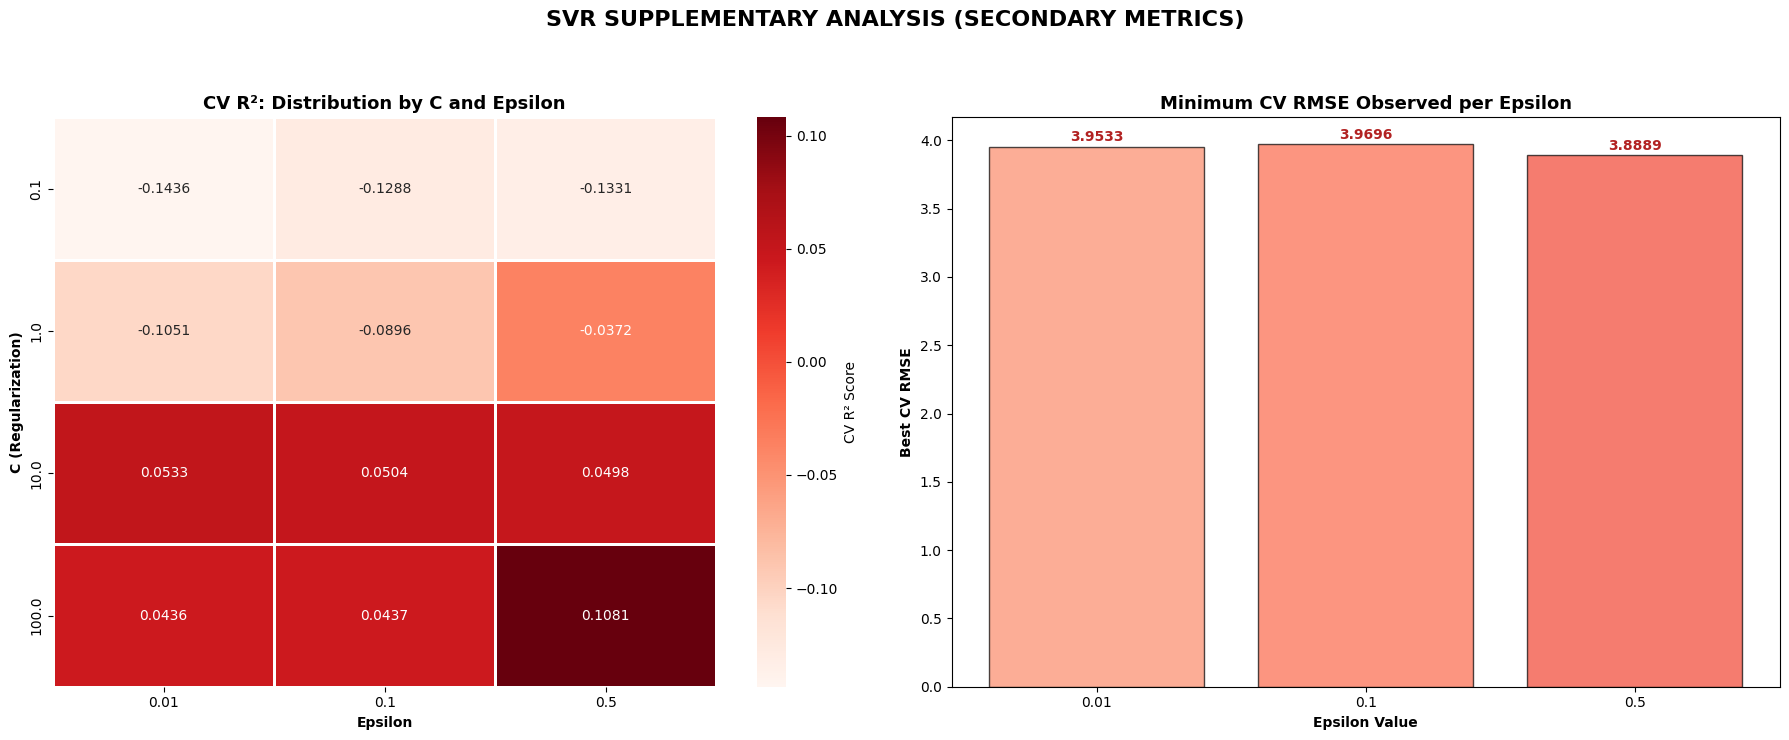


✓ 2 Secondary SVR plots rendered.


In [130]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# ============================================================================================
# QUESTION 4.b) SVR HYPERPARAMETER COMPARISON AND VISUALIZATION (0.5 points)
# ============================================================================================

# 0. Prepare pivot table and epsilon summary based on CV metrics
pivot_r2 = svr_results_df.pivot(index="C", columns="Epsilon", values="CV_R2")
epsilon_best = svr_results_df.groupby("Epsilon")["CV_RMSE"].min()

# 1. Create figure with 1 row and 2 columns
fig, axes = plt.subplots(1, 2, figsize=(18, 7))
fig.suptitle("SVR SUPPLEMENTARY ANALYSIS (SECONDARY METRICS)", fontsize=16, fontweight="bold", y=1.05)

# --- FIGURE 1: HEATMAP OF CV R² ---
sns.heatmap(
    pivot_r2,
    annot=True,
    fmt=".4f",
    cmap="Reds",
    ax=axes[0],
    cbar_kws={"label": "CV R² Score"},
    linewidths=1,
    linecolor="white"
)
axes[0].set_title("CV R²: Distribution by C and Epsilon", fontweight="bold", fontsize=13)
axes[0].set_xlabel("Epsilon", fontweight="bold")
axes[0].set_ylabel("C (Regularization)", fontweight="bold")

# --- FIGURE 2: MINIMUM CV RMSE OBSERVED PER EPSILON ---
bar_colors = plt.cm.Reds(np.linspace(0.4, 0.6, len(epsilon_best)))
axes[1].bar(
    range(len(epsilon_best)),
    epsilon_best.values,
    color=bar_colors,
    edgecolor="black",
    alpha=0.7
)
axes[1].set_xticks(range(len(epsilon_best)))
axes[1].set_xticklabels(epsilon_best.index)
axes[1].set_title("Minimum CV RMSE Observed per Epsilon", fontweight="bold", fontsize=13)
axes[1].set_xlabel("Epsilon Value", fontweight="bold")
axes[1].set_ylabel("Best CV RMSE", fontweight="bold")

# Add value labels on top of bars
for i, v in enumerate(epsilon_best.values):
    axes[1].text(
        i,
        v + (max(epsilon_best.values) * 0.01),
        f"{v:.4f}",
        ha="center",
        fontweight="bold",
        color="#B22222"
    )

plt.tight_layout()
plt.show()

print("\n✓ 2 Secondary SVR plots rendered.")

### Question 4.c. SVM vs Other Regression Methods Comparison

In [131]:
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_error
import pandas as pd
import numpy as np

# ============================================================================================
# QUESTION 4.c) SVR VS OTHER REGRESSION METHODS COMPARISON (0.5 points)
# ============================================================================================
print("\n" + "=" * 100)
print("EMPIRICAL COMPARISON: TRAINING OTHER MODELS ON SAME DATA")
print("=" * 100)

# 1. Linear Regression (scaled data)
lr_model = LinearRegression()
lr_model.fit(X_train_scaled, y_train)
y_lr_pred = lr_model.predict(X_test_scaled)

lr_rmse = np.sqrt(mean_squared_error(y_test, y_lr_pred))
lr_r2 = r2_score(y_test, y_lr_pred)
lr_mae = mean_absolute_error(y_test, y_lr_pred)

# 2. Decision Tree (reference model for comparison, unscaled data)
dt_model_cmp = DecisionTreeRegressor(
    random_state=42,
    max_depth=5,
    min_samples_split=2,
    min_samples_leaf=5
)
dt_model_cmp.fit(X_train, y_train)
y_dt_pred = dt_model_cmp.predict(X_test)

dt_rmse = np.sqrt(mean_squared_error(y_test, y_dt_pred))
dt_r2 = r2_score(y_test, y_dt_pred)
dt_mae = mean_absolute_error(y_test, y_dt_pred)

# 3. Random Forest (reference model for comparison, unscaled data)
rf_model = RandomForestRegressor(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)
rf_model.fit(X_train, y_train)
y_rf_pred = rf_model.predict(X_test)

rf_rmse = np.sqrt(mean_squared_error(y_test, y_rf_pred))
rf_r2 = r2_score(y_test, y_rf_pred)
rf_mae = mean_absolute_error(y_test, y_rf_pred)

# ============================================================================================
# COMPARISON TABLE
# ============================================================================================
comparison_results = pd.DataFrame({
    "Model": ["Linear Regression", "SVR (Best by CV)", "Decision Tree", "Random Forest"],
    "Test_RMSE": [lr_rmse, best_svr["Test_RMSE"], dt_rmse, rf_rmse],
    "Test_MAE": [lr_mae, best_svr["Test_MAE"], dt_mae, rf_mae],
    "Test_R2": [lr_r2, best_svr["Test_R2"], dt_r2, rf_r2],
    "Training_Time": ["Very Fast", "Slow", "Fast", "Medium"],
    "Interpretability": ["Excellent", "Low", "High", "Low"]
})

print("\n" + comparison_results.to_string(index=False))

best_model_name = comparison_results.loc[comparison_results["Test_RMSE"].idxmin(), "Model"]
print(f"\nBest Model by Test RMSE: {best_model_name}")


EMPIRICAL COMPARISON: TRAINING OTHER MODELS ON SAME DATA

            Model  Test_RMSE  Test_MAE  Test_R2 Training_Time Interpretability
Linear Regression   8.060922  3.122298 0.297168     Very Fast        Excellent
 SVR (Best by CV)   6.107800  2.494017 0.596492          Slow              Low
    Decision Tree   7.472946  2.662850 0.395960          Fast             High
    Random Forest   6.246004  2.495691 0.578025        Medium              Low

Best Model by Test RMSE: SVR (Best by CV)


## Question 5: Decision Tree Regression Model Development
### Question 5.a Decision Tree Model Building and Hyperparameter Optimization

In [132]:
from sklearn.tree import DecisionTreeRegressor
from sklearn.model_selection import TimeSeriesSplit
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
import pandas as pd
import numpy as np

# ============================================================================================
# QUESTION 5.a) DECISION TREE MODEL BUILDING AND HYPERPARAMETER OPTIMIZATION (1.0 points)
# ============================================================================================
print("=" * 100)
print("DECISION TREE MODEL DEVELOPMENT (27 CONFIGURATIONS)")
print("=" * 100)

# Make sure the training set is ordered by time for TimeSeriesSplit
train_order = train_df.sort_values("date").index
X_train_tree = X_train.loc[train_order]
y_train_tree = y_train.loc[train_order]

# Keep test set for final evaluation only
X_test_tree = X_test.copy()
y_test_tree = y_test.copy()

# Hyperparameter grid
max_depth_values = [3, 5, 8]
min_samples_split_values = [2, 5, 10]
min_samples_leaf_values = [1, 2, 5]

results_dt = []

print(f"\nTraining Decision Tree models with TimeSeriesSplit CV...")
print(f"max_depth values to test: {max_depth_values}")
print(f"min_samples_split values to test: {min_samples_split_values}")
print(f"min_samples_leaf values to test: {min_samples_leaf_values}")
print(f"Total combinations: {len(max_depth_values) * len(min_samples_split_values) * len(min_samples_leaf_values)}")

# Time-series cross-validation on training set only
tscv = TimeSeriesSplit(n_splits=3)

for depth in max_depth_values:
    for min_split in min_samples_split_values:
        for min_leaf in min_samples_leaf_values:
            cv_rmse_scores = []
            cv_mae_scores = []
            cv_r2_scores = []

            # Cross-validation on TRAIN only
            for tr_idx, val_idx in tscv.split(X_train_tree):
                X_tr = X_train_tree.iloc[tr_idx]
                X_val = X_train_tree.iloc[val_idx]
                y_tr = y_train_tree.iloc[tr_idx]
                y_val = y_train_tree.iloc[val_idx]

                dt_model = DecisionTreeRegressor(
                    max_depth=depth,
                    min_samples_split=min_split,
                    min_samples_leaf=min_leaf,
                    random_state=42
                )
                dt_model.fit(X_tr, y_tr)

                y_val_pred = dt_model.predict(X_val)

                cv_rmse_scores.append(np.sqrt(mean_squared_error(y_val, y_val_pred)))
                cv_mae_scores.append(mean_absolute_error(y_val, y_val_pred))
                cv_r2_scores.append(r2_score(y_val, y_val_pred))

            # Refit on full training set
            final_dt_model = DecisionTreeRegressor(
                max_depth=depth,
                min_samples_split=min_split,
                min_samples_leaf=min_leaf,
                random_state=42
            )
            final_dt_model.fit(X_train_tree, y_train_tree)

            y_train_pred = final_dt_model.predict(X_train_tree)
            y_test_pred = final_dt_model.predict(X_test_tree)

            train_rmse = np.sqrt(mean_squared_error(y_train_tree, y_train_pred))
            test_rmse = np.sqrt(mean_squared_error(y_test_tree, y_test_pred))
            train_mae = mean_absolute_error(y_train_tree, y_train_pred)
            test_mae = mean_absolute_error(y_test_tree, y_test_pred)
            train_r2 = r2_score(y_train_tree, y_train_pred)
            test_r2 = r2_score(y_test_tree, y_test_pred)

            results_dt.append({
                "Max_Depth": depth,
                "Min_Samples_Split": min_split,
                "Min_Samples_Leaf": min_leaf,
                "CV_RMSE": np.mean(cv_rmse_scores),
                "CV_MAE": np.mean(cv_mae_scores),
                "CV_R2": np.mean(cv_r2_scores),
                "Train_RMSE": train_rmse,
                "Test_RMSE": test_rmse,
                "Train_MAE": train_mae,
                "Test_MAE": test_mae,
                "Train_R2": train_r2,
                "Test_R2": test_r2,
                "Train_Test_RMSE_Gap": test_rmse - train_rmse,
                "Model": final_dt_model
            })

            print(f"✓ Depth={depth:2d}, MinSplit={min_split:2d}, MinLeaf={min_leaf:2d} → CV_RMSE={np.mean(cv_rmse_scores):7.3f}, Test_RMSE={test_rmse:7.3f}, Test_R²={test_r2:7.4f}")

# ============================================================================================
# DECISION TREE HYPERPARAMETER COMPARISON TABLE
# ============================================================================================
dt_results_df = pd.DataFrame(results_dt).drop("Model", axis=1)

print("\n" + "=" * 100)
print("DECISION TREE HYPERPARAMETER COMPARISON TABLE")
print("=" * 100)

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 1400)

print(
    dt_results_df.to_string(
        index=False,
        justify="center",
        float_format=lambda x: f"{x:9.4f}"
    )
)

# ============================================================================================
# BEST DECISION TREE MODEL
# ============================================================================================
best_dt_idx = dt_results_df["CV_RMSE"].idxmin()
best_dt = results_dt[best_dt_idx]
best_dt_model = best_dt["Model"]

print(f"\n{'='*100}")
print("BEST DECISION TREE MODEL")
print(f"{'='*100}")
print(f"Best hyperparameters (selected by CV_RMSE): max_depth={best_dt['Max_Depth']}, min_samples_split={best_dt['Min_Samples_Split']}, min_samples_leaf={best_dt['Min_Samples_Leaf']}")
print(f"CV RMSE : {best_dt['CV_RMSE']:.4f}")
print(f"Test RMSE: {best_dt['Test_RMSE']:.4f}")
print(f"Test R²  : {best_dt['Test_R2']:.4f}")
print(f"Test MAE : {best_dt['Test_MAE']:.4f}")
print(f"Number of leaves: {best_dt_model.get_n_leaves()}")

DECISION TREE MODEL DEVELOPMENT (27 CONFIGURATIONS)

Training Decision Tree models with TimeSeriesSplit CV...
max_depth values to test: [3, 5, 8]
min_samples_split values to test: [2, 5, 10]
min_samples_leaf values to test: [1, 2, 5]
Total combinations: 27
✓ Depth= 3, MinSplit= 2, MinLeaf= 1 → CV_RMSE=  4.134, Test_RMSE=  7.355, Test_R²= 0.4149
✓ Depth= 3, MinSplit= 2, MinLeaf= 2 → CV_RMSE=  4.134, Test_RMSE=  7.543, Test_R²= 0.3846
✓ Depth= 3, MinSplit= 2, MinLeaf= 5 → CV_RMSE=  4.088, Test_RMSE=  7.472, Test_R²= 0.3962
✓ Depth= 3, MinSplit= 5, MinLeaf= 1 → CV_RMSE=  4.134, Test_RMSE=  7.543, Test_R²= 0.3846
✓ Depth= 3, MinSplit= 5, MinLeaf= 2 → CV_RMSE=  4.134, Test_RMSE=  7.543, Test_R²= 0.3846
✓ Depth= 3, MinSplit= 5, MinLeaf= 5 → CV_RMSE=  4.088, Test_RMSE=  7.472, Test_R²= 0.3962
✓ Depth= 3, MinSplit=10, MinLeaf= 1 → CV_RMSE=  4.134, Test_RMSE=  7.543, Test_R²= 0.3846
✓ Depth= 3, MinSplit=10, MinLeaf= 2 → CV_RMSE=  4.134, Test_RMSE=  7.543, Test_R²= 0.3846
✓ Depth= 3, MinSplit=10


VISUALIZING DECISION TREE STRUCTURE


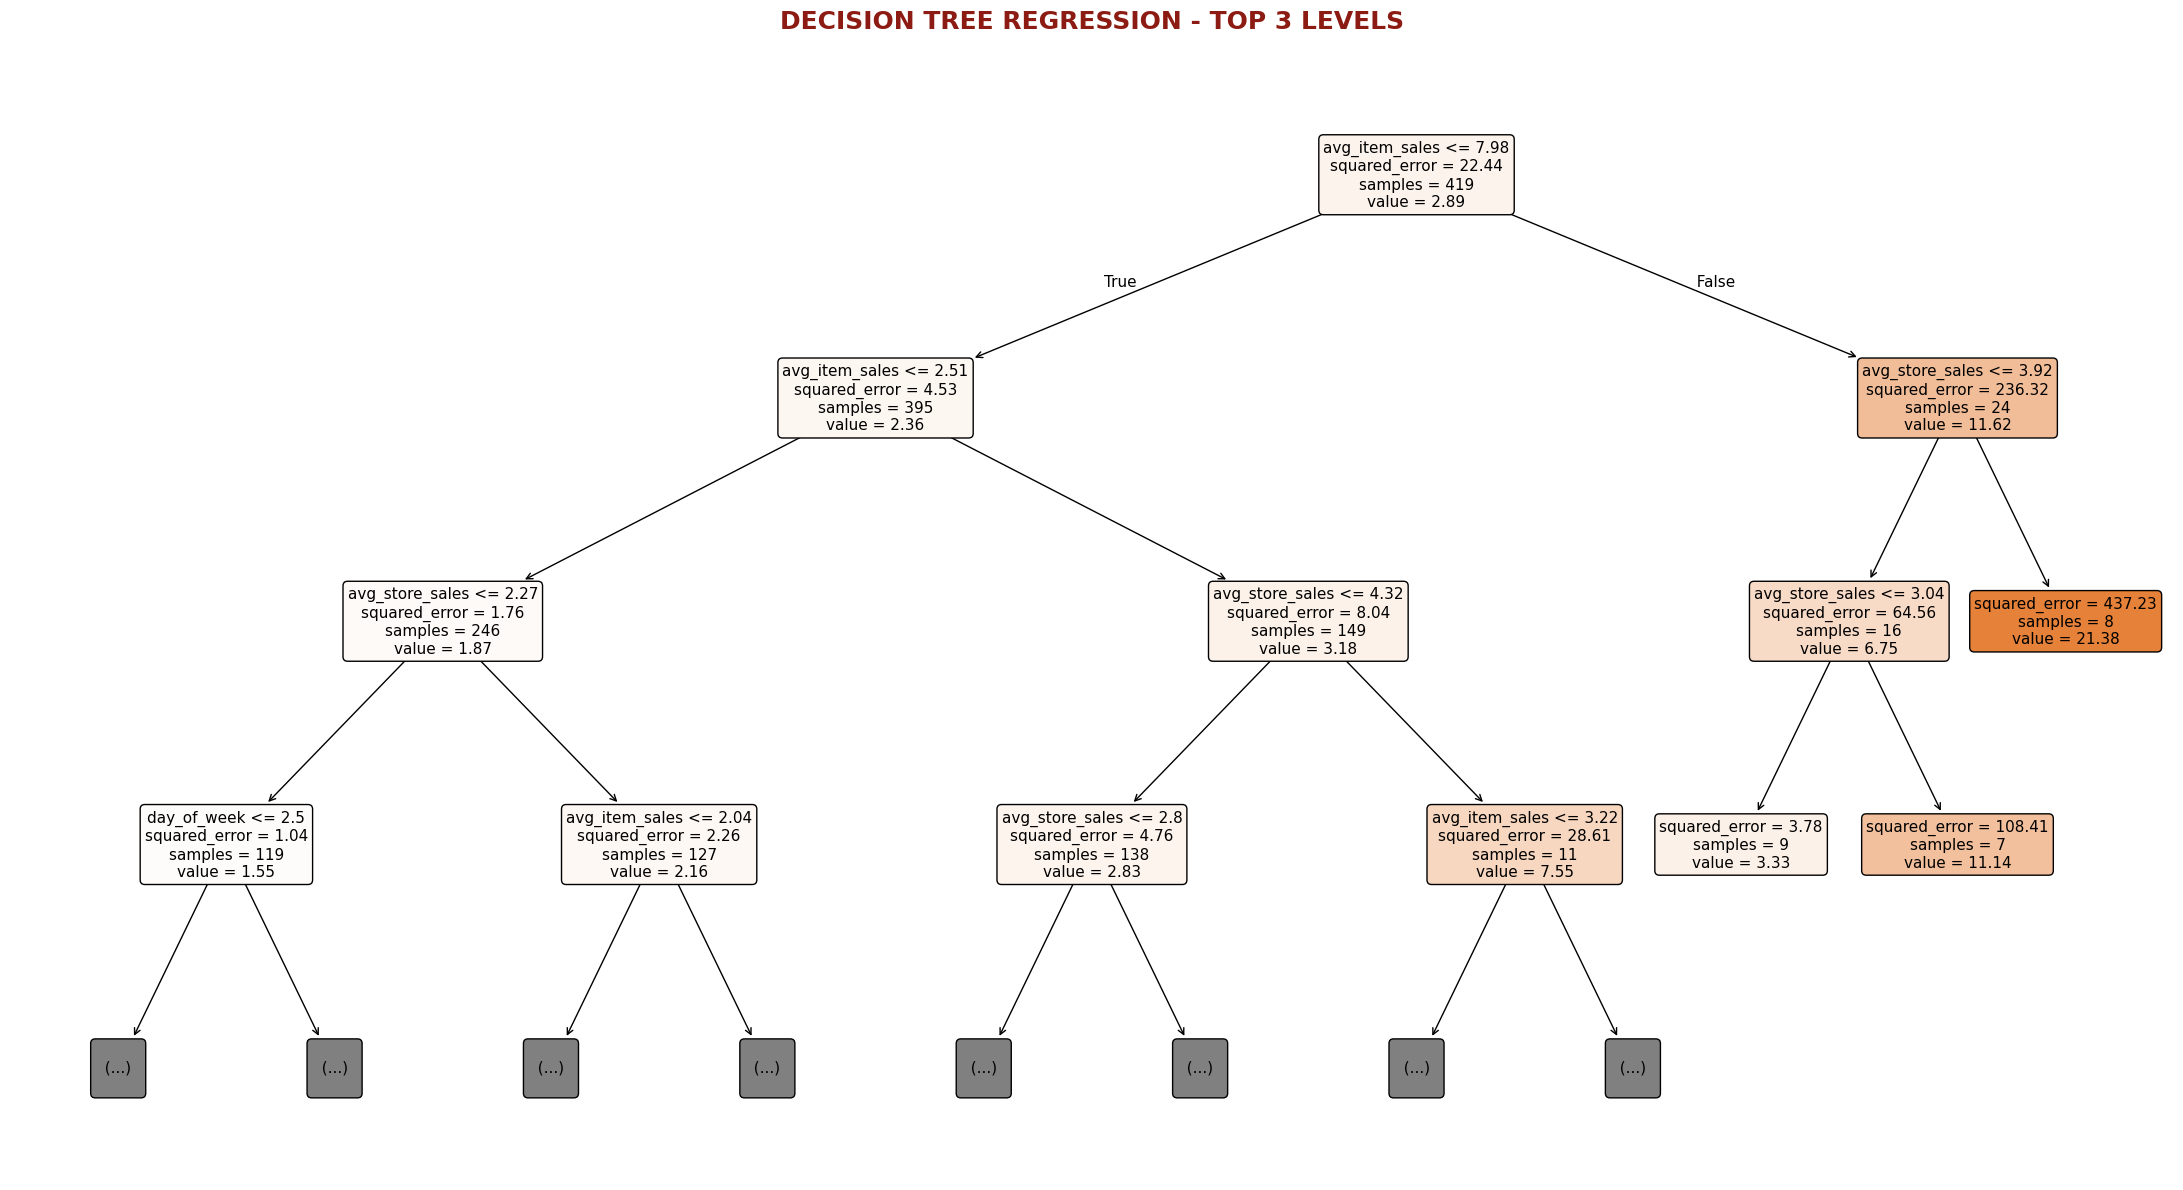


DECISION TREE RULES (TOP 3 LEVELS)
|--- avg_item_sales <= 7.98
|   |--- avg_item_sales <= 2.51
|   |   |--- avg_store_sales <= 2.27
|   |   |   |--- day_of_week <= 2.50
|   |   |   |   |--- truncated branch of depth 5
|   |   |   |--- day_of_week >  2.50
|   |   |   |   |--- truncated branch of depth 5
|   |   |--- avg_store_sales >  2.27
|   |   |   |--- avg_item_sales <= 2.04
|   |   |   |   |--- truncated branch of depth 5
|   |   |   |--- avg_item_sales >  2.04
|   |   |   |   |--- truncated branch of depth 4
|   |--- avg_item_sales >  2.51
|   |   |--- avg_store_sales <= 4.32
|   |   |   |--- avg_store_sales <= 2.80
|   |   |   |   |--- truncated branch of depth 5
|   |   |   |--- avg_store_sales >  2.80
|   |   |   |   |--- truncated branch of depth 5
|   |   |--- avg_store_sales >  4.32
|   |   |   |--- avg_item_sales <= 3.22
|   |   |   |   |--- value: [6.80]
|   |   |   |--- avg_item_sales >  3.22
|   |   |   |   |--- value: [8.17]
|--- avg_item_sales >  7.98
|   |--- avg_sto

In [133]:
import matplotlib.pyplot as plt
from sklearn.tree import plot_tree, export_text

# ============================================================================================
# QUESTION 5.b) DECISION TREE VISUALIZATION AND NODE INTERPRETATION (1.0 point)
# ============================================================================================
print("\n" + "=" * 100)
print("VISUALIZING DECISION TREE STRUCTURE")
print("=" * 100)

feature_names = X_train.columns.tolist()

# 1. Visualize the best decision tree (top 3 levels)
fig, ax = plt.subplots(figsize=(22, 12))

plot_tree(
    best_dt_model,
    max_depth=3,
    feature_names=feature_names,
    ax=ax,
    fontsize=11,
    filled=True,
    rounded=True,
    precision=2
)

plt.title(
    "DECISION TREE REGRESSION - TOP 3 LEVELS",
    fontsize=18,
    fontweight="bold",
    pad=25,
     color="#8C1C13"
)
plt.tight_layout()
plt.show()

# 2. Export tree rules as text
print("\n" + "=" * 100)
print("DECISION TREE RULES (TOP 3 LEVELS)")
print("=" * 100)

tree_rules = export_text(best_dt_model, feature_names=feature_names, max_depth=3)
print(tree_rules)